# Lesson 7 · Statistical Visualisation with Seaborn
### Distributions, comparisons, relationships, heatmaps and correlation: in a few lines

| | |
|---|---|
| **Type** | LESSON 07 |
| **Time** | about 120 minutes |
| **Level** | Intermediate |
| **Prerequisites** | Lesson 6 (Matplotlib) and Lesson 5 (groupby, pivot) |

**By the end of this notebook you will be able to:**

- Explain what Seaborn adds on top of Matplotlib and why *tidy (long) data* matters
- Draw distribution plots: histogram, KDE, ECDF, and compare groups
- Draw categorical plots: count, bar (with confidence intervals), box, violin, strip
- Draw relational plots with `hue`, `size`, `style` and facet into small multiples
- Visualise correlation: heatmaps, pair plots, joint plots, and read them *critically*
- Spot why correlation of trending series can fool you

## 🛠️ Setup
Run this cell first. It imports the tools and loads the data every problem below relies on.

In [1]:

import sys; sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from course_utils import DATA_DIR, check, check_plot

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.figsize": (9, 4.5), "figure.dpi": 100})

prices = pd.read_csv(DATA_DIR / "market_prices_clean.csv", parse_dates=["date"])
prices["year"] = prices["date"].dt.year
prices["month"] = prices["date"].dt.month
weather = pd.read_json(DATA_DIR / "weather_monthly.json")

# A county-month panel for maize: price, volume and weather side by side
_mz = (prices[prices["crop"] == "Maize"].groupby(["county", "year", "month"], as_index=False)
       .agg(avg_price=("price_kes_per_kg", "mean"), volume_t=("volume_kg", lambda s: s.sum() / 1000)))
panel = _mz.merge(weather, on=["county", "year", "month"], how="left")
print("Setup complete ✔  prices", prices.shape, "| panel", panel.shape)


Setup complete ✔  prices (15048, 11) | panel (384, 7)


## 👋 Matplotlib with a statistics degree

Matplotlib is the *engine*: total control, but you assemble everything by hand (loops over groups, manual legends, manual colours).
**Seaborn** sits on top and speaks *data*: you hand it a DataFrame and say *which column goes where*.

```python
# Matplotlib: ~8 lines (loop, filter, label, legend)        # Seaborn: 1 line
sns.boxplot(data=prices, x="crop", y="price_kes_per_kg")
```

Seaborn also does **statistics for you**: it aggregates, bootstraps confidence intervals, fits regression lines and estimates densities.

### The one rule: tidy data
Seaborn expects **long / tidy** data: *each row is one observation, each column is one variable.* Our `prices` table already is: one row = one (date, market, crop) price.
If your data are wide (one column per year), reshape with `melt` (Lesson 5).

### Two families of functions

| Family | Examples | Returns | Layout |
|---|---|---|---|
| **Axes-level** | `histplot, boxplot, barplot, scatterplot, lineplot, heatmap` | a Matplotlib `Axes` | draws on *one* `ax` (you can pass `ax=`) |
| **Figure-level** | `displot, catplot, relplot, lmplot, pairplot, jointplot` | a `FacetGrid`-type object | makes its **own figure**, can split into panels with `col=` / `row=` |

Everything Seaborn draws is still Matplotlib underneath, so `ax.set_title(...)` etc. still work.

## 1 · Distributions: what does one variable look like?

### 1.1 `histplot` (with `hue`, `kde`, `stat`)

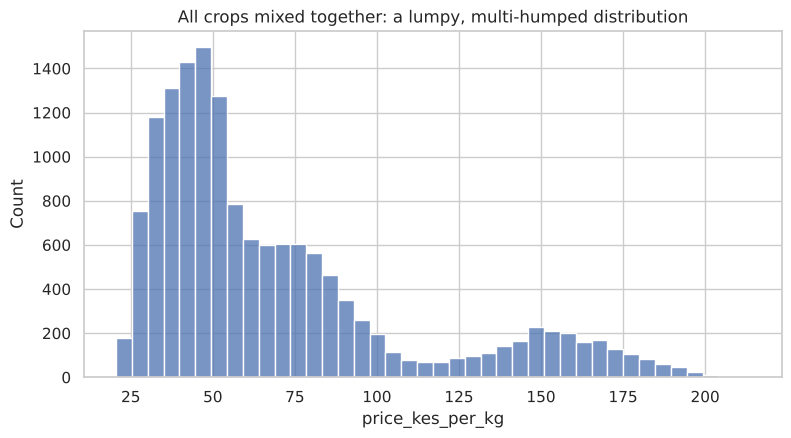

In [2]:
fig, ax = plt.subplots()
sns.histplot(data=prices, x="price_kes_per_kg", bins=40, ax=ax)
ax.set_title("All crops mixed together: a lumpy, multi-humped distribution")
plt.show()

> 🧠 **Pause and predict.** Why so lumpy? Because we mixed eight crops with very different price levels. The honest question is *'what is the distribution of each crop's price?'*. Let's split with `hue`.

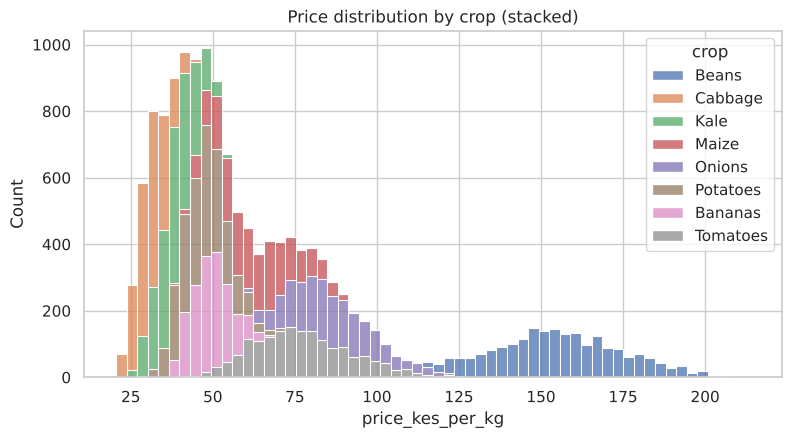

In [3]:
fig, ax = plt.subplots()
sns.histplot(data=prices, x="price_kes_per_kg", hue="crop", bins=60, multiple="stack", ax=ax)
ax.set_title("Price distribution by crop (stacked)")
plt.show()

### 1.2 Density (`kdeplot`), ECDF, and facets

A **KDE** (kernel density estimate) is a smoothed histogram. An **ECDF** shows "what share of records are at or below this price?": no bins to choose!

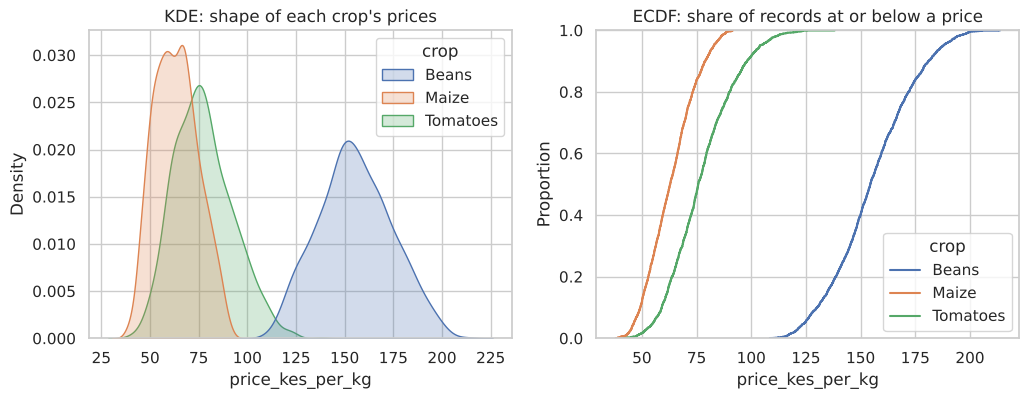

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sub = prices[prices["crop"].isin(["Maize", "Tomatoes", "Beans"])]
sns.kdeplot(data=sub, x="price_kes_per_kg", hue="crop", fill=True, common_norm=False, ax=axes[0])
axes[0].set_title("KDE: shape of each crop's prices")
sns.ecdfplot(data=sub, x="price_kes_per_kg", hue="crop", ax=axes[1])
axes[1].set_title("ECDF: share of records at or below a price")
plt.show()

> 💡 **Intuition.** Read an ECDF with a ruler: draw a vertical line at 100 KES; where it crosses each curve is the share of records at or below 100. Maize is ~100% (never above 100): beans only ~0%.

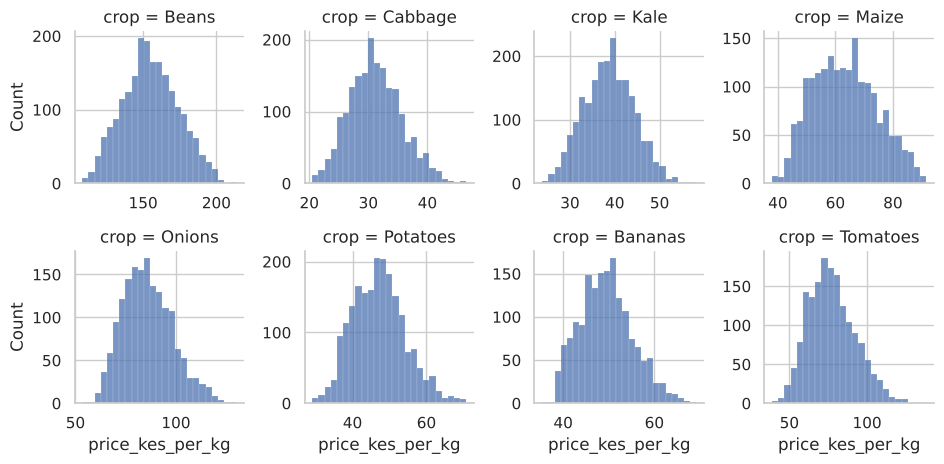

In [5]:
sns.displot(data=prices, x="price_kes_per_kg", col="crop", col_wrap=4, bins=25, height=2.4, common_bins=False, facet_kws=dict(sharex=False, sharey=False))
plt.show()

### 1.3 Comparing years: did the drought shift the *whole* distribution?

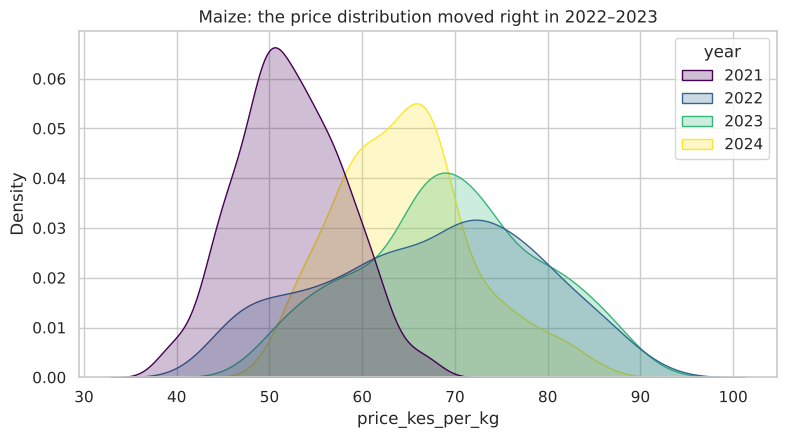

In [6]:
mz = prices[prices["crop"] == "Maize"]
fig, ax = plt.subplots()
sns.kdeplot(data=mz, x="price_kes_per_kg", hue="year", palette="viridis", fill=True, alpha=0.25, common_norm=False, ax=ax)
ax.set_title("Maize: the price distribution moved right in 2022–2023")
plt.show()

## 2 · Categorical plots: comparing groups

### 2.1 `countplot`: how many records per category?

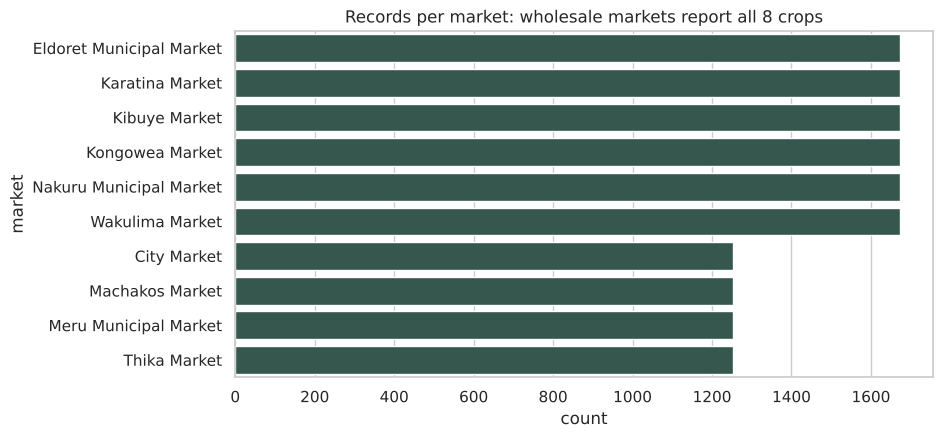

In [7]:
fig, ax = plt.subplots()
sns.countplot(data=prices, y="market", order=prices["market"].value_counts().index, color="#2F5D50", ax=ax)
ax.set_title("Records per market: wholesale markets report all 8 crops")
plt.show()

### 2.2 `barplot`: the mean **with uncertainty**

Unlike Matplotlib's `bar`, Seaborn's `barplot` **aggregates** (mean by default) and draws a **95% confidence interval**.

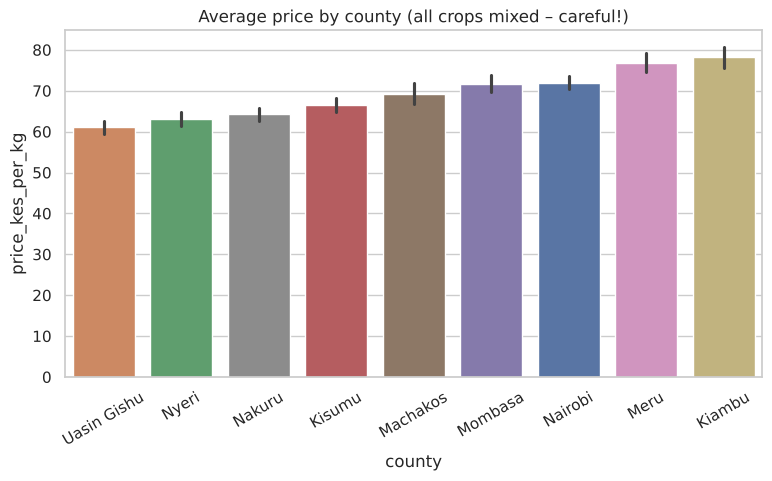

In [8]:
fig, ax = plt.subplots()
sns.barplot(data=prices, x="county", y="price_kes_per_kg", hue="county", legend=False, errorbar=("ci", 95),
            order=prices.groupby("county")["price_kes_per_kg"].mean().sort_values().index, ax=ax)
ax.set_title("Average price by county (all crops mixed – careful!)")
ax.tick_params(axis="x", rotation=30)
plt.show()

> ⚠️ **Common mistake.** This chart mixes crops, so a county looks 'expensive' mainly if it *happens to sell more beans*. **Always ask what is hiding inside an average.** Fix: compare within one crop, or split with `hue`/`col`.

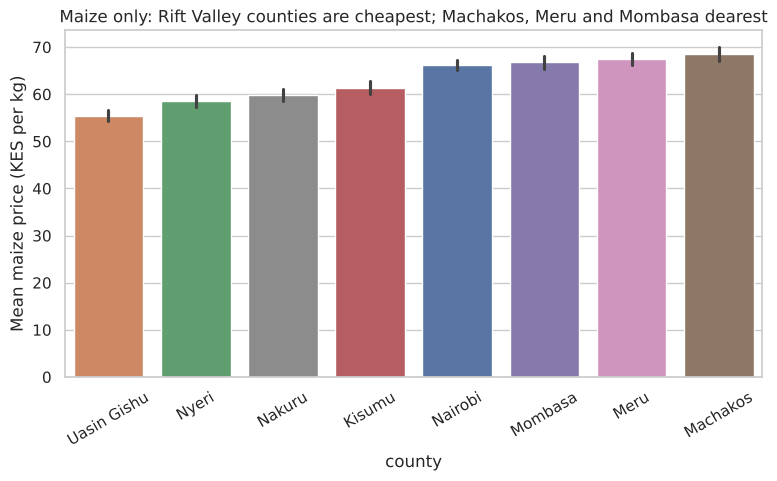

In [9]:
fig, ax = plt.subplots()
sns.barplot(data=prices[prices["crop"] == "Maize"], x="county", y="price_kes_per_kg", hue="county", legend=False,
            order=prices[prices["crop"] == "Maize"].groupby("county")["price_kes_per_kg"].mean().sort_values().index, ax=ax)
ax.set_title("Maize only: Rift Valley counties are cheapest; Machakos, Meru and Mombasa dearest")
ax.set_ylabel("Mean maize price (KES per kg)")
ax.tick_params(axis="x", rotation=30)
plt.show()

### 2.3 `boxplot`, `violinplot`, `stripplot`: show the whole distribution, not just the mean

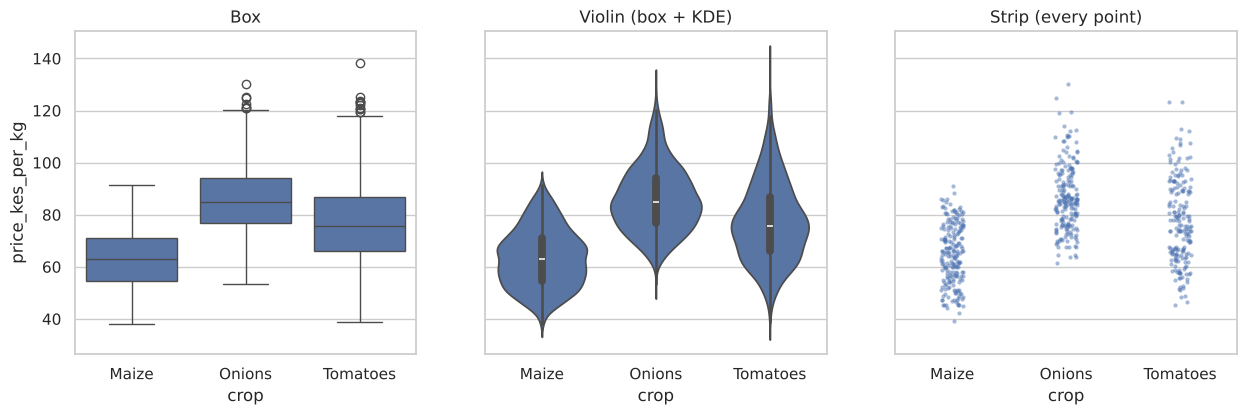

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
sub = prices[prices["crop"].isin(["Maize", "Tomatoes", "Onions"])]
sns.boxplot(data=sub, x="crop", y="price_kes_per_kg", ax=axes[0]);      axes[0].set_title("Box")
sns.violinplot(data=sub, x="crop", y="price_kes_per_kg", ax=axes[1]);   axes[1].set_title("Violin (box + KDE)")
sns.stripplot(data=sub.sample(600, random_state=1), x="crop", y="price_kes_per_kg", size=3, alpha=0.5, ax=axes[2]); axes[2].set_title("Strip (every point)")
plt.show()

> 💡 **Intuition.** A bar of the mean hides spread, skew, gaps and outliers. Box plots show quartiles; violins show shape; strip plots show the actual points. When groups are small, show the points.

`hue` splits each category further, for an instant two-factor comparison:

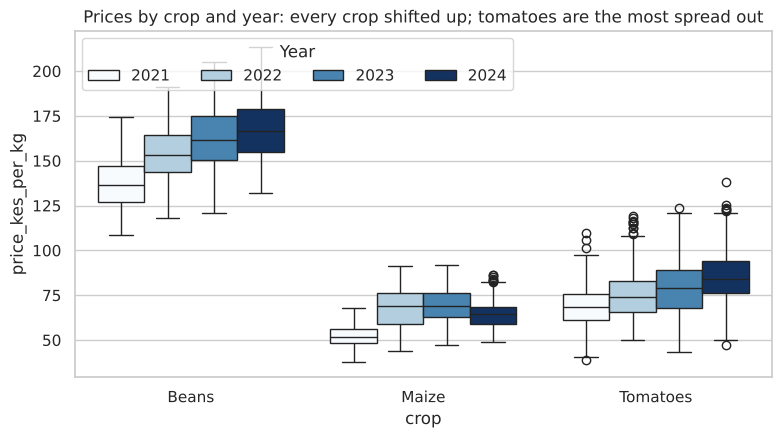

In [11]:
fig, ax = plt.subplots()
sns.boxplot(data=prices[prices["crop"].isin(["Maize", "Beans", "Tomatoes"])], x="crop", y="price_kes_per_kg", hue="year", palette="Blues", ax=ax)
ax.set_title("Prices by crop and year: every crop shifted up; tomatoes are the most spread out")
ax.legend(title="Year", ncol=4, loc="upper left")
plt.show()

## 3 · Relational plots: number vs number

### 3.1 `scatterplot` with `hue`, `size`, `style`

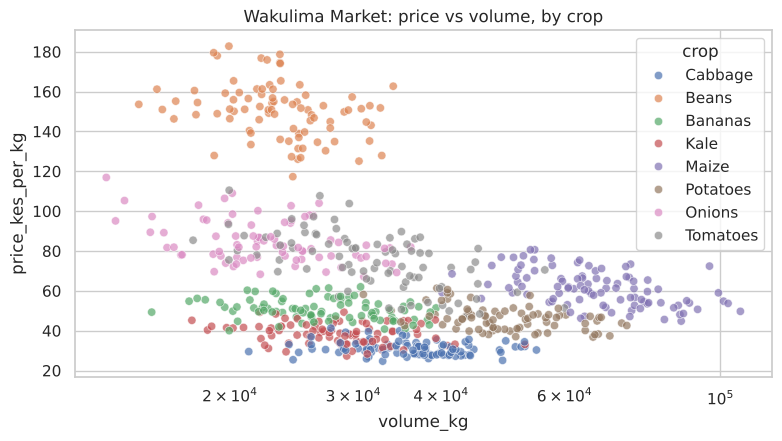

In [12]:
t = prices[prices["market"] == "Wakulima Market"].sample(700, random_state=0)
fig, ax = plt.subplots()
sns.scatterplot(data=t, x="volume_kg", y="price_kes_per_kg", hue="crop", alpha=0.7, ax=ax)
ax.set_xscale("log")
ax.set_title("Wakulima Market: price vs volume, by crop")
plt.show()

> 🧠 **Pause and predict.** Pooled across crops there is *no tidy line*: crops form separate clouds (beans high, cabbage low). A single trend line through all of them would be nonsense. Colour by crop revealed the structure. This is **Simpson's-paradox territory**: groups hide relationships.

### 3.2 `lineplot`: aggregates and confidence bands automatically

Give `lineplot` *many rows per x* and it draws the **mean** and a **confidence band**.

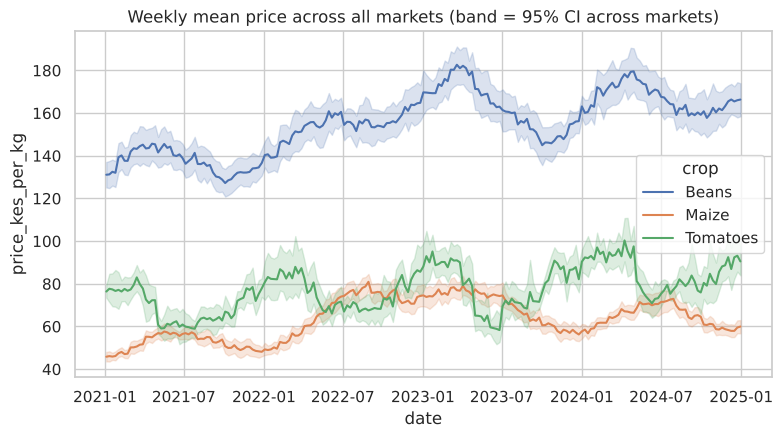

In [13]:
fig, ax = plt.subplots()
sns.lineplot(data=prices[prices["crop"].isin(["Maize", "Beans", "Tomatoes"])], x="date", y="price_kes_per_kg", hue="crop", ax=ax)
ax.set_title("Weekly mean price across all markets (band = 95% CI across markets)")
plt.show()

### 3.3 Small multiples with `relplot`

One chart per category, same axes, easy to compare: a favourite tool of data analysts.

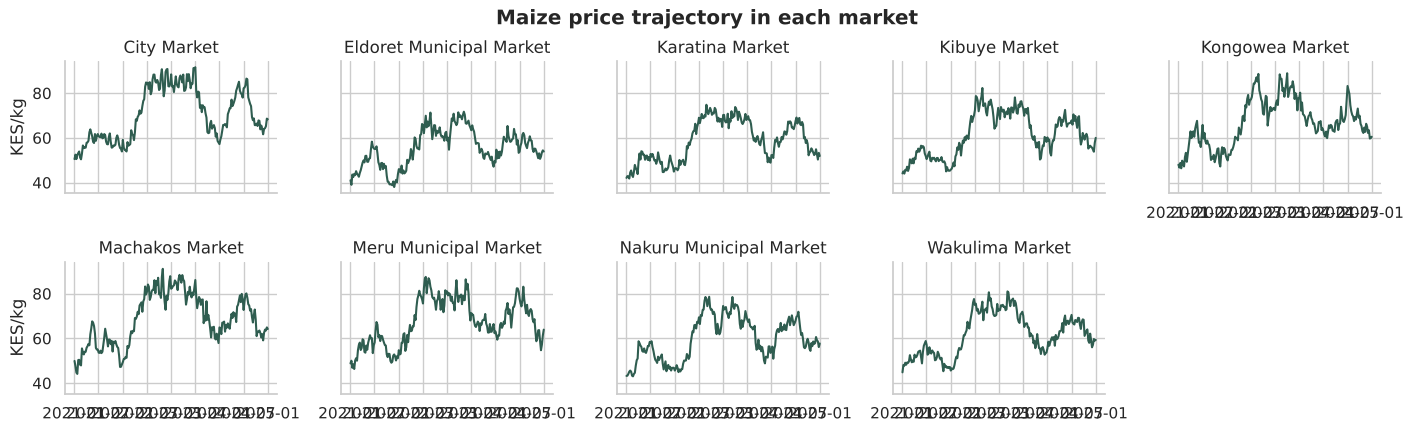

In [14]:
g = sns.relplot(data=prices[prices["crop"] == "Maize"], x="date", y="price_kes_per_kg", col="market", col_wrap=5,
                kind="line", height=2.2, aspect=1.3, color="#2F5D50")
g.set_titles("{col_name}")
g.set_axis_labels("", "KES/kg")
g.figure.suptitle("Maize price trajectory in each market", y=1.03, fontweight="bold")
plt.show()

## 4 · Regression plots: trend lines with uncertainty

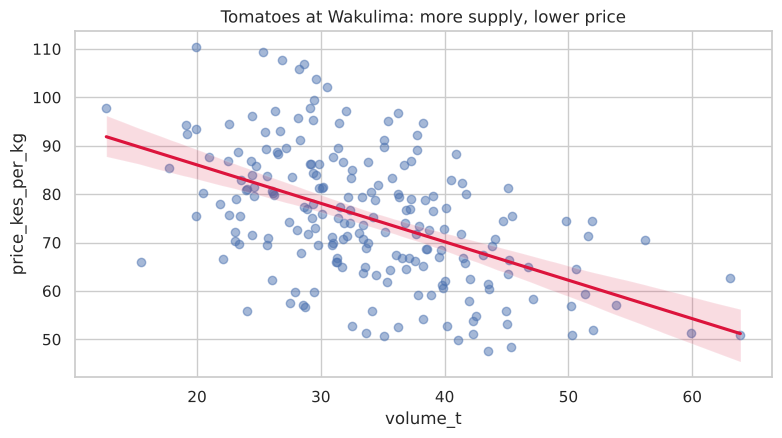

correlation: -0.51


In [15]:
tw = prices[(prices["crop"] == "Tomatoes") & (prices["market"] == "Wakulima Market")].copy()
tw["volume_t"] = tw["volume_kg"] / 1000
fig, ax = plt.subplots()
sns.regplot(data=tw, x="volume_t", y="price_kes_per_kg", scatter_kws=dict(alpha=0.5), line_kws=dict(color="crimson"), ax=ax)
ax.set_title("Tomatoes at Wakulima: more supply, lower price")
plt.show()
print("correlation:", round(tw["volume_t"].corr(tw["price_kes_per_kg"]), 2))

> 📝 **Note.** The shaded band around the line is the uncertainty of the *fitted line*. A narrow band does not mean the line explains the data well: look at the spread of the points too.

## 5 · Visualising correlation

### 5.1 The correlation coefficient in 60 seconds

Pearson's **r** measures *linear* association between two numbers, from **−1** (perfect opposite) through **0** (no linear link) to **+1** (perfect together).

| r | Reading |
|---|---|
| 0.0 – 0.2 | essentially none |
| 0.2 – 0.4 | weak |
| 0.4 – 0.7 | moderate |
| 0.7 – 1.0 | strong |

Three warnings: **r only sees straight lines** (a perfect U-shape has r≈0); **outliers can fake or hide it**; **r says nothing about causation**.

### 5.2 A correlation heatmap

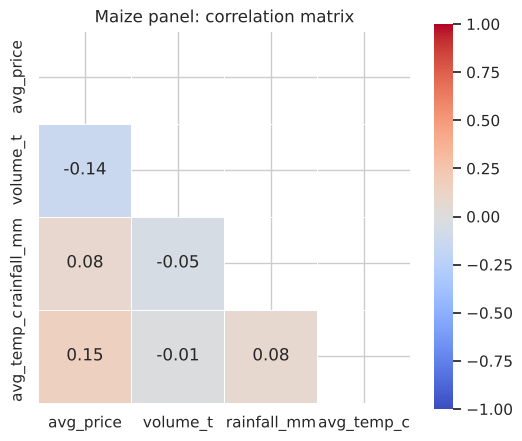

In [16]:
cols = ["avg_price", "volume_t", "rainfall_mm", "avg_temp_c"]
corr = panel[cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))          # hide the redundant upper triangle

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True, linewidths=0.5, ax=ax)
ax.set_title("Maize panel: correlation matrix")
plt.show()

Colour tells you the sign and strength at a glance (blue = negative, red = positive). Always fix `vmin=-1, vmax=1, center=0` so *white means zero* and colours are comparable across charts.

> 🧠 **Pause and predict.** `avg_temp_c` and `avg_price` are (weakly) positively correlated, r ≈ 0.15. Does *heat raise maize prices*? Temperature barely varies within a county but differs a lot *between* counties (Mombasa is hot and pricey; the Rift Valley is cool and cheap). So temperature may be **standing in for 'which county'**: a classic case of *confounding*. Colour the points by county and see.

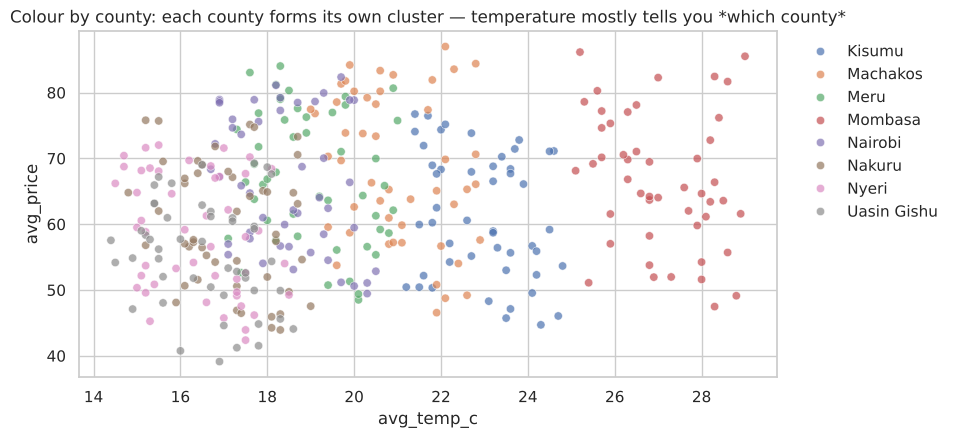

In [17]:
fig, ax = plt.subplots()
sns.scatterplot(data=panel, x="avg_temp_c", y="avg_price", hue="county", alpha=0.7, ax=ax)
ax.set_title("Colour by county: each county forms its own cluster; temperature mostly tells you *which county*")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.show()

### 5.3 When trends fake a correlation

Two series that both **rise over time** are strongly correlated even if unrelated. Prices of different crops share ~7% yearly inflation (plus the same drought):

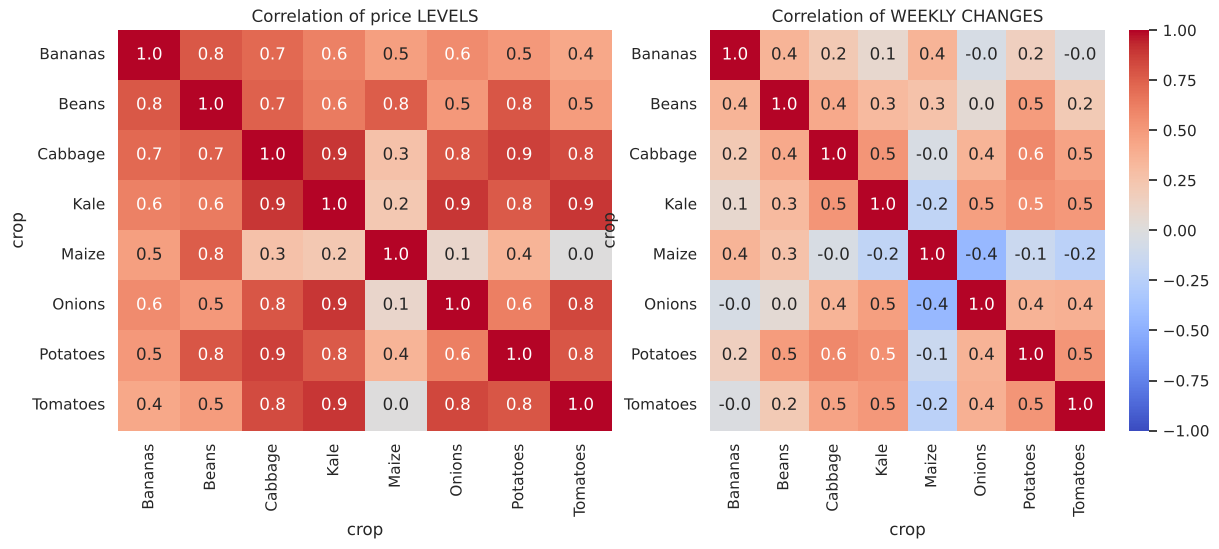

In [18]:
wide = prices.pivot_table(index="date", columns="crop", values="price_kes_per_kg", aggfunc="mean")
levels = wide.corr()
changes = wide.pct_change().dropna().corr()

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
sns.heatmap(levels, annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1, center=0, cbar=False, ax=axes[0]); axes[0].set_title("Correlation of price LEVELS")
sns.heatmap(changes, annot=True, fmt=".1f", cmap="coolwarm", vmin=-1, vmax=1, center=0, ax=axes[1]);            axes[1].set_title("Correlation of WEEKLY CHANGES")
plt.show()

> 💡 **Intuition.** In levels, nearly every crop 'moves with' almost every other (0.5–0.9): shared inflation + shared drought. In weekly *changes* the picture is far more discriminating: many pairs drop to about 0, maize even moves *against* onions, and what remains (the leafy vegetables (cabbage, kale, onions, tomatoes) still at ≈0.5) is a **real short-term signal** (they react to the same rain and supply shocks). **Detrend (differences, % changes) before correlating time series; what survives is the interesting part.**

> 🤖 **Why machine learning cares.** A model fed highly redundant, trending features may look brilliant on training data and fail on new data: the correlations were just a shared clock. Always check correlation on *changes* for time series.

### 5.4 `pairplot` and `jointplot`: many relationships at once

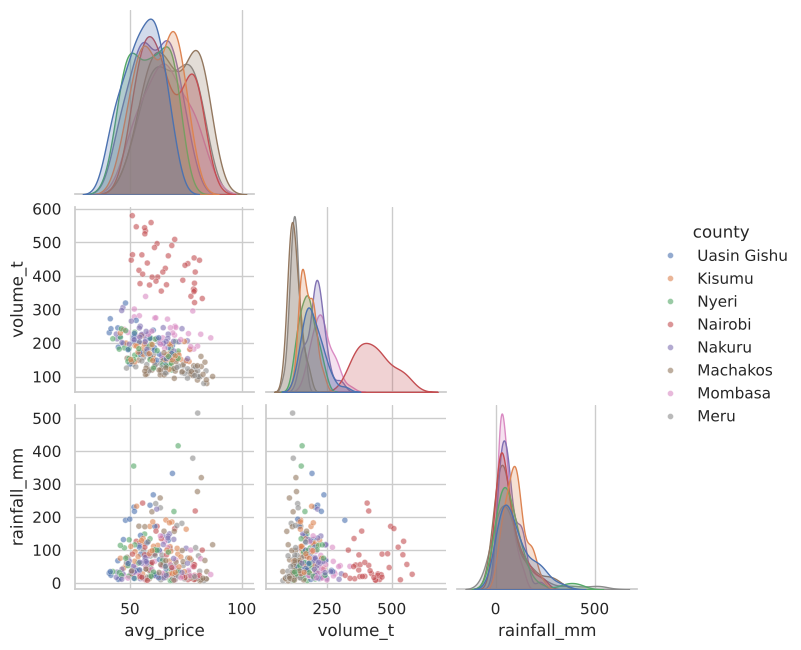

In [19]:
sns.pairplot(panel.dropna(subset=["rainfall_mm"]).sample(300, random_state=3),
             vars=["avg_price", "volume_t", "rainfall_mm"], hue="county", corner=True, plot_kws=dict(alpha=0.6, s=18), height=2.2)
plt.show()

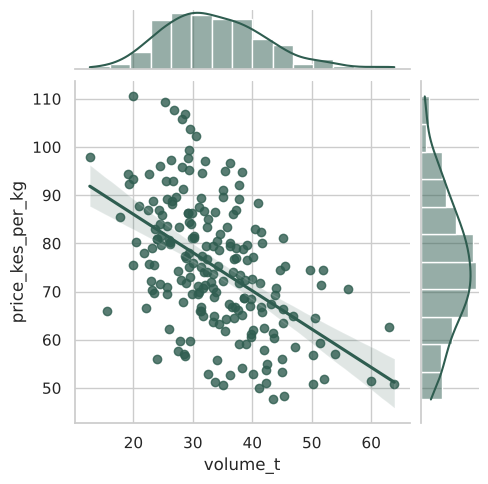

In [20]:
sns.jointplot(data=tw, x="volume_t", y="price_kes_per_kg", kind="reg", height=5, color="#2F5D50")
plt.show()

## 6 · Heatmaps of *pivot tables*: seeing seasonality

A heatmap isn't only for correlations: any two-way table of numbers becomes readable as colour. **Question:** *in which month is each crop dearest?*

To remove the long-run trend, divide each price by the average of its own series **in that year** (1.0 = a normal week):

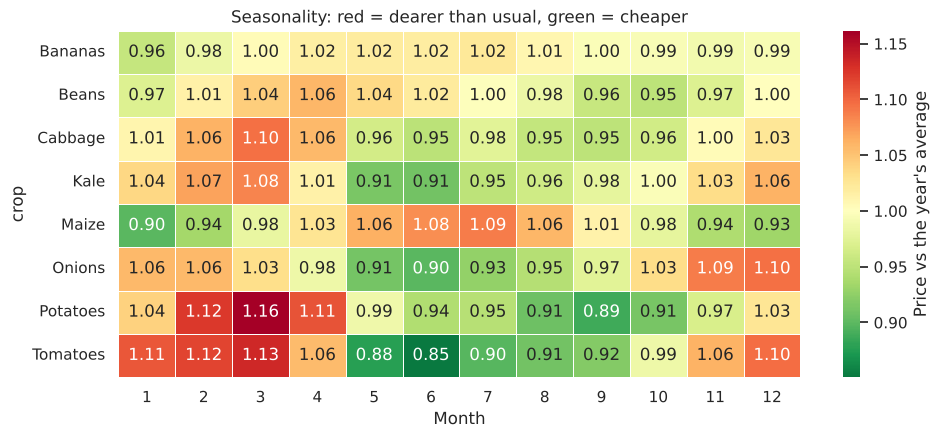

In [21]:
p = prices.copy()
p["relative_price"] = p["price_kes_per_kg"] / p.groupby(["crop", "market", "year"])["price_kes_per_kg"].transform("mean")
season = p.pivot_table(index="crop", columns="month", values="relative_price", aggfunc="mean")

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.heatmap(season, cmap="RdYlGn_r", center=1.0, annot=True, fmt=".2f", linewidths=0.4, cbar_kws=dict(label="Price vs the year's average"), ax=ax)
ax.set_title("Seasonality: red = dearer than usual, green = cheaper")
ax.set_xlabel("Month")
plt.show()

**Palettes in one minute.** *Sequential* (light→dark) for magnitudes (`"Blues"`, `"viridis"`); *diverging* (two hues meeting at a neutral centre) for above/below a reference (`"coolwarm"`, `"RdYlGn_r"`); *qualitative* for unordered categories (`"deep"`, `"Set2"`, `"colorblind"`). Reserve red/green carefully: ~8% of men can't tell them apart.

---
# 🧑‍🏫 Worked examples

## Worked example 1: "Did the drought hit every crop equally?"

> **Thinking steps.** (1) Different crops have different price levels, so compare **indices** (2021 average = 100). (2) One line per crop → `lineplot` with `hue`. (3) Shade the drought. (4) Title = the finding.

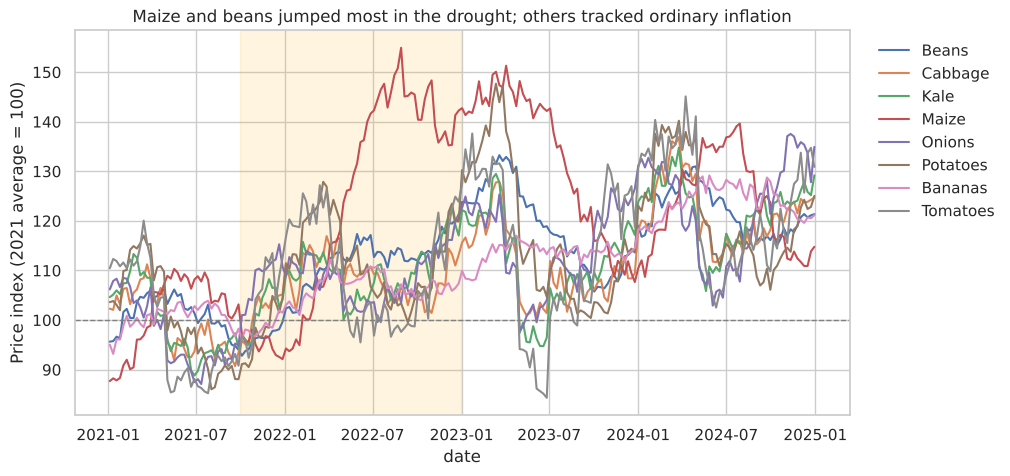

In [22]:
d = prices.copy()
base = d[d["year"] == 2021].groupby("crop")["price_kes_per_kg"].mean()
d["index"] = d["price_kes_per_kg"] / d["crop"].map(base) * 100

fig, ax = plt.subplots(figsize=(10, 5))
sns.lineplot(data=d, x="date", y="index", hue="crop", errorbar=None, ax=ax)
ax.axvspan(pd.Timestamp("2021-10-01"), pd.Timestamp("2022-12-31"), color="orange", alpha=0.12)
ax.axhline(100, color="grey", linewidth=1, linestyle="--")
ax.set_title("Maize and beans jumped most in the drought; others tracked ordinary inflation")
ax.set_ylabel("Price index (2021 average = 100)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.show()

## Worked example 2: "Which markets are the 'price leaders'?"

> **Thinking steps.** (1) Compare markets within **one** crop to avoid mixing. (2) Show the distribution, not just the mean: boxplot. (3) Sort by median. (4) Horizontal layout for long names.

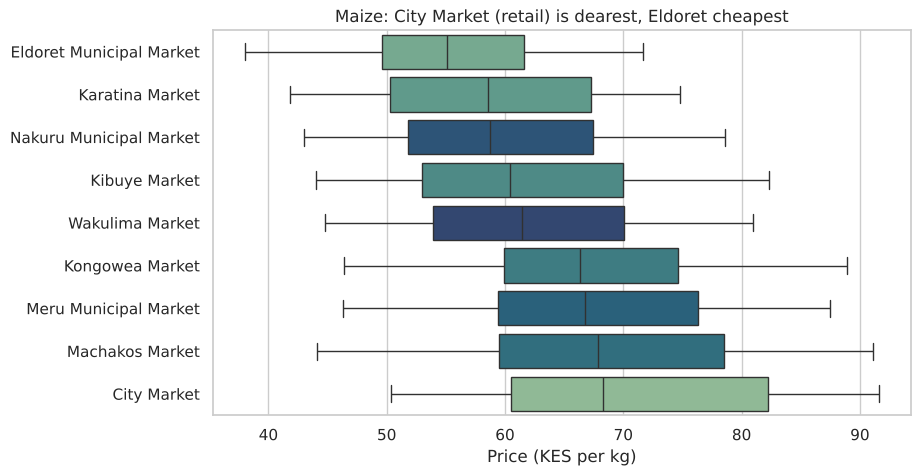

In [23]:
mz = prices[prices["crop"] == "Maize"]
order = mz.groupby("market")["price_kes_per_kg"].median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=mz, y="market", x="price_kes_per_kg", order=order, hue="market", legend=False, palette="crest", ax=ax)
ax.set_title("Maize: City Market (retail) is dearest, Eldoret cheapest")
ax.set_xlabel("Price (KES per kg)"); ax.set_ylabel("")
plt.show()

---
# 🏋️ Problems

Chart problems end with a `check_plot` that verifies the essentials. Value problems use `answer`/`check`. Start every figure with `fig, ax = plt.subplots()` and pass `ax=ax` to Seaborn.

### 🎨 Problem 7.1: Tomato histogram by market type

Draw a **histogram of Tomatoes prices** (`bins=30`) from `prices`, with a **KDE curve** (`kde=True`) and **`hue='crop'`-free** (just tomatoes). Add a title.

<details>
<summary>💡 Hint 1</summary>

Filter `prices` to tomatoes first.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`sns.histplot(data=t, x='price_kes_per_kg', bins=30, kde=True, ax=ax)`, then `ax.set_title(...)`.

</details>

❌ 07-p1: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel); expected at least 30 bar/patch objects but found 0.


False

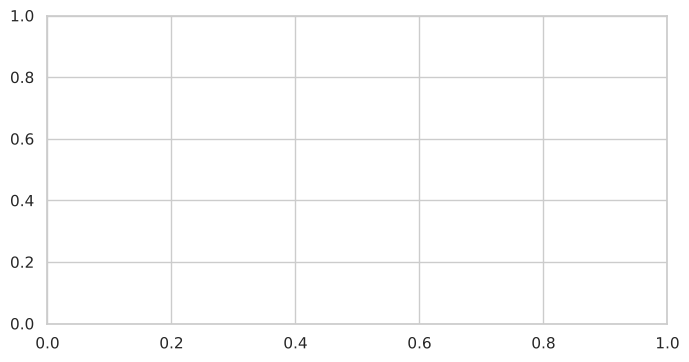

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, min_bars=30, name='07-p1')

### 🎨 Problem 7.2: Maize by county - box plot

Draw a **box plot** of **Maize** prices for each **county** (`x='county'`, `y='price_kes_per_kg'`) with a title, readable x tick labels (rotate them) and a y-label with units.

<details>
<summary>💡 Hint 1</summary>

Filter maize. `sns.boxplot(data=mz, x='county', y='price_kes_per_kg', ax=ax)`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`ax.tick_params(axis='x', rotation=30)`.

</details>

❌ 07-p2: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel); expected at least 9 line(s) but found 0.


False

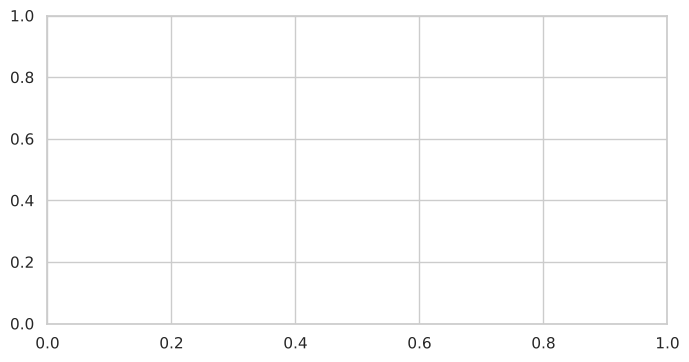

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, min_lines=9, name='07-p2')

### 🎨 Problem 7.3: Bar chart with confidence intervals

Using `sns.barplot`, show the **mean price by crop** (x = crop). Give it a title and a y-label with units.

<details>
<summary>💡 Hint 1</summary>

`sns.barplot(data=prices, x='crop', y='price_kes_per_kg', ax=ax)` aggregates the mean for you.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

Optionally add `order=` sorted by the mean, and `hue='crop', legend=False` to colour each bar.

</details>

❌ 07-p3: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel); expected at least 8 bar/patch objects but found 0.


False

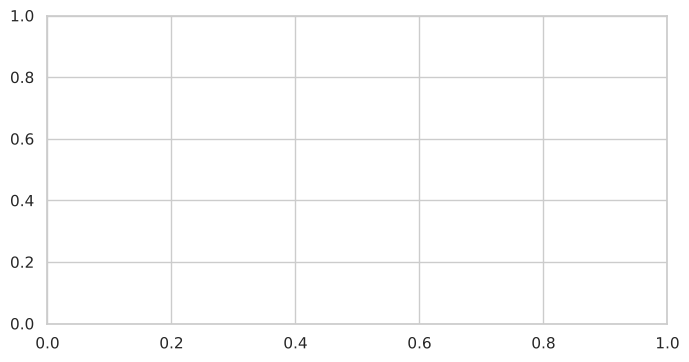

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, min_bars=8, name='07-p3')

### 🎨 Problem 7.4: Price index lines

For **Maize, Beans and Tomatoes**, compute a price index where the **2021 mean of each crop = 100**, and draw **three lines** (one per crop, `hue='crop'`, `errorbar=None`) against `date`. Title, y-label and legend required.

<details>
<summary>💡 Hint 1</summary>

`base = d[d['year']==2021].groupby('crop')['price_kes_per_kg'].mean()` then `d['index'] = d['price_kes_per_kg'] / d['crop'].map(base) * 100`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`sns.lineplot(data=d, x='date', y='index', hue='crop', errorbar=None, ax=ax)`: the legend is created automatically.

</details>

❌ 07-p4: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel); expected 3 line(s) but found 0; add a legend (ax.legend or a hue/label argument).


False

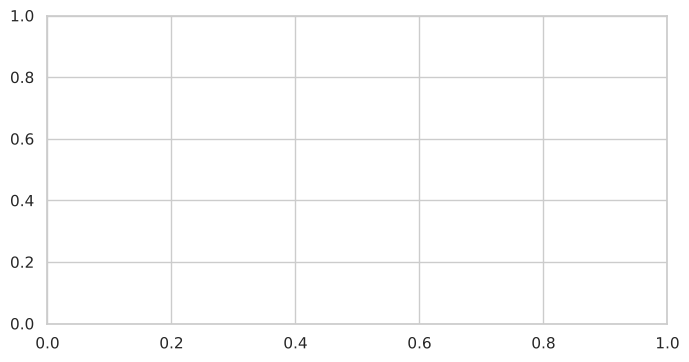

In [27]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, n_lines=3, legend=True, name='07-p4')

### 🎨 Problem 7.5: Crop × year heatmap

Build a pivot table of **mean price** (rows = crop, columns = year) and draw it as an **annotated heatmap** (`annot=True`, `fmt='.0f'`, sequential colormap). Add a title.

<details>
<summary>💡 Hint 1</summary>

`prices.pivot_table(index='crop', columns='year', values='price_kes_per_kg', aggfunc='mean')`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`sns.heatmap(pt, annot=True, fmt='.0f', cmap='YlGnBu', ax=ax)`.

</details>

❌ 07-p5: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel).


False

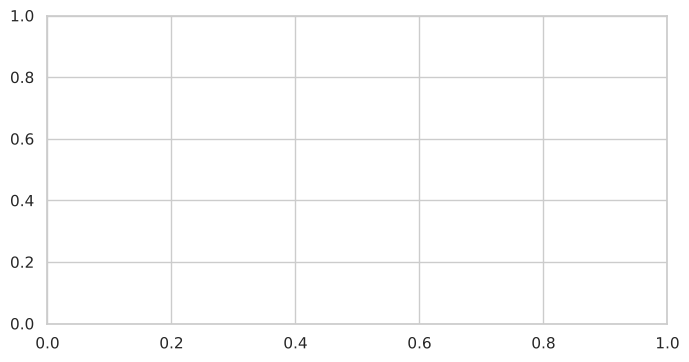

In [28]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, name='07-p5')

### 🎨 Problem 7.6: Correlation heatmap of the maize panel

Compute the correlation matrix of `['avg_price', 'volume_t', 'rainfall_mm', 'avg_temp_c']` in `panel` and draw it as a heatmap with annotations, `cmap='coolwarm'`, `vmin=-1`, `vmax=1`. Add a title.

<details>
<summary>💡 Hint 1</summary>

`corr = panel[cols].corr()`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=ax)`. A heatmap's axis labels may be empty: that's fine, the tick labels carry the names.

</details>

❌ 07-p6: add a title (ax.set_title).


False

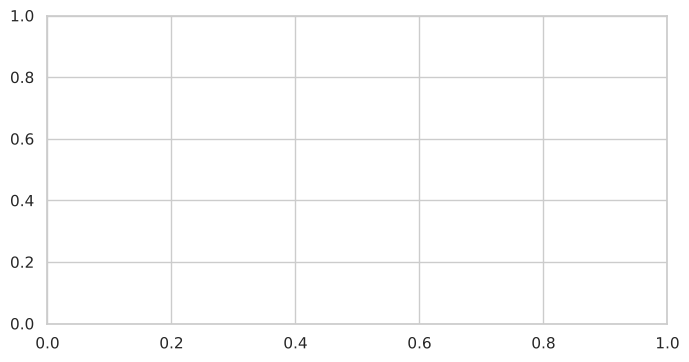

In [29]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, xlabel=False, ylabel=False, name='07-p6')

### 🧩 Problem 7.7: Strongest correlate of price

In the `panel` DataFrame, which of the columns `volume_t`, `rainfall_mm`, `avg_temp_c` has the **largest absolute correlation** with `avg_price`? Return the column name.

*Expected type:* a string.

<details>
<summary>💡 Hint 1</summary>

`panel[['avg_price','volume_t','rainfall_mm','avg_temp_c']].corr()['avg_price']` gives the correlations with price.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

Drop `avg_price` itself, take `.abs()`, then `.idxmax()`.

</details>

*Auto-check id:* `07-p7`  ·  *Set the variable `answer`, then run the cell.*

In [30]:
# ✍️ Your turn: compute the result and store it in `answer`
answer = None

check('07-p7', answer)

⏳ 07-p7: you haven't set `answer` yet. Read the problem, try it, then run this cell again.


False

### 🎨 Problem 7.8: Regression plot

Draw a **`sns.regplot`** of **price (y) against volume in tonnes (x)** for **Kale at Wakulima Market**. Title and axis labels required.

<details>
<summary>💡 Hint 1</summary>

Filter two conditions and create `volume_t = volume_kg / 1000`.

</details>

<details>
<summary>💡 Hint 2 (the big nudge)</summary>

`sns.regplot(data=k, x='volume_t', y='price_kes_per_kg', ax=ax)`. Then set the title and labels.

</details>

❌ 07-p8: add a title (ax.set_title); label the x-axis (ax.set_xlabel); label the y-axis (ax.set_ylabel); expected at least 100 scatter points but found 0.


False

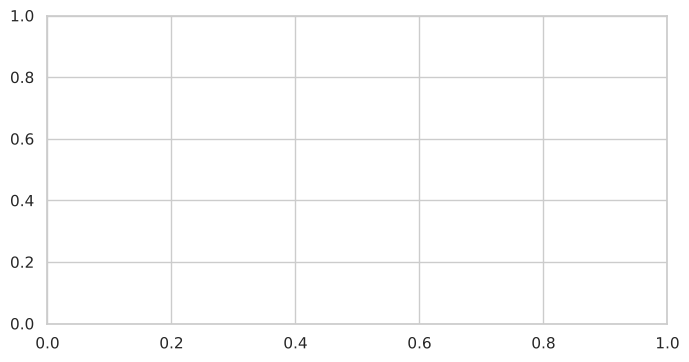

In [31]:
fig, ax = plt.subplots(figsize=(8, 4))
# ✍️ Your turn: draw on `ax`

check_plot(ax, min_points=100, name='07-p8')

### ✍️ Problem 7.9: Levels vs changes

In section 5.3 almost every crop correlated moderately-to-strongly with every other in **price levels**, but the **weekly changes** told a more selective story (many pairs near zero, some negative, vegetables still positive). Explain *why* in 3–4 sentences, and say which version you would trust to decide whether *tomato prices help predict onion prices*.

✍️ *Write your answer here (double-click to edit):*



## ✅ Check your understanding

Answer in your head (or out loud!) first, *then* open the answer.

**Q1. What is the difference between axes-level and figure-level Seaborn functions? Give an example of each.**

<details>
<summary>Show answer</summary>

Axes-level (`histplot`, `boxplot`, `heatmap`) draw onto a Matplotlib `Axes` you can supply with `ax=`. Figure-level (`displot`, `relplot`, `catplot`, `pairplot`) create their own figure and can facet into panels with `col=`/`row=`.

</details>

**Q2. Why does Seaborn want 'tidy' data?**

<details>
<summary>Show answer</summary>

Because you map *columns to roles* (`x`, `y`, `hue`, `col`). That only works when each variable is one column and each observation one row.

</details>

**Q3. What does `sns.barplot` draw that `ax.bar` doesn't?**

<details>
<summary>Show answer</summary>

It aggregates (mean by default) and draws a bootstrapped 95% confidence interval for you.

</details>

**Q4. A heatmap's colours go from white at 0 to red at +1 and blue at −1. Which arguments guarantee that?**

<details>
<summary>Show answer</summary>

`cmap='coolwarm'`, `center=0`, `vmin=-1`, `vmax=1`.

</details>

**Q5. Temperature and maize price correlate weakly positively (r ≈ 0.15). Why shouldn't you conclude heat raises prices?**

<details>
<summary>Show answer</summary>

Temperature differs mostly *between* counties, and counties differ in market type and price level (e.g. hot Mombasa is pricey, cool Uasin Gishu is cheap). Temperature stands in for *which county*: a confounder. Look within counties before drawing conclusions.

</details>

## 🧾 Cheat-sheet

```python
sns.set_theme(style="whitegrid")
sns.histplot(data=df, x="v", hue="g", bins=30, kde=True)       # distribution        sns.kdeplot / sns.ecdfplot
sns.boxplot / sns.violinplot / sns.stripplot(data=df, x="cat", y="v")                # compare groups
sns.barplot(data=df, x="cat", y="v", errorbar=("ci", 95))      # mean ± CI           sns.countplot(data=df, x="cat")
sns.scatterplot(data=df, x="a", y="b", hue="g", size="s")      # relationship        sns.regplot(data=df, x="a", y="b")
sns.lineplot(data=df, x="date", y="v", hue="g")                # trend (+ CI band)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
sns.pairplot(df, vars=[...], hue="g", corner=True)             # many pairs         sns.jointplot(data=df, x=, y=, kind="reg")
sns.relplot(data=df, x=, y=, col="g", kind="line")             # small multiples    sns.displot(data=df, x=, col="g")
```

## ➡️ Next up
**Lesson 8; The EDA Playbook.** You now own the tools. The next lesson teaches the *method*: a repeatable routine to understand *any* unfamiliar dataset and turn what you see into hypotheses and ML-ready decisions.